BEM参考解

=== 多核 BEM 求解无限域受压圆孔问题 ===
孔径 a=1.0m, 外边界 L=80.0m, 内压 P0=1.0e+06Pa, E=1.0e+09Pa, nu=0.3
边界单元数: 外边界=40, 内圆孔=180, 总计=220
组装系统矩阵...
矩阵组装耗时: 2.576 s
求解线性方程组...
提取近场物理场与有限差分应力...
数据提取完成，耗时: 1.193 s


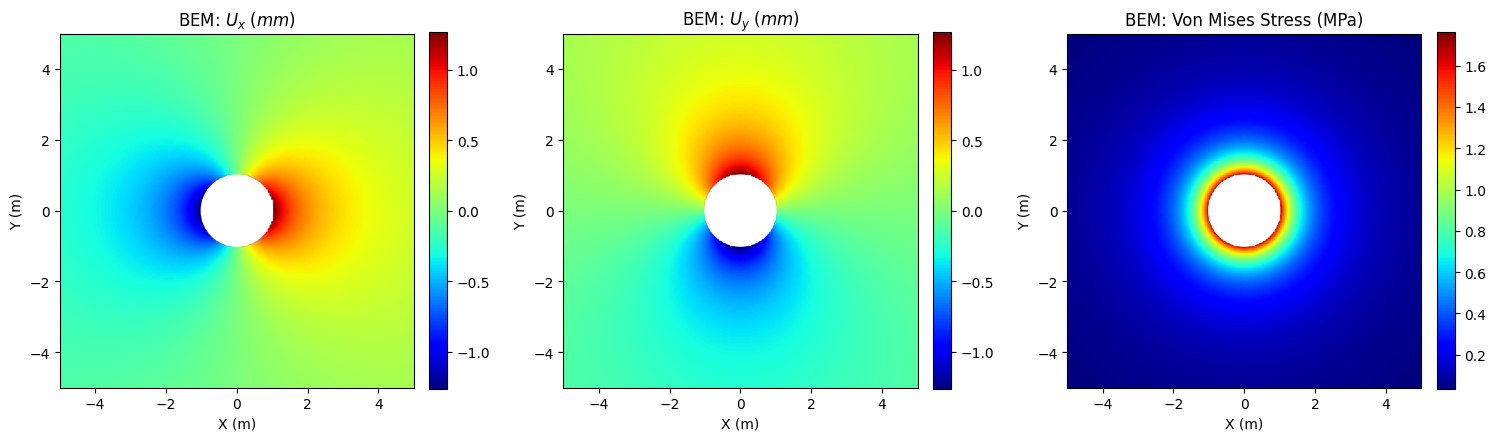

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit, prange
import time

# ==========================================
# 1. 物理参数与网格参数 (严格对齐论文截图)
# ==========================================
a = 1.0              # 圆孔半径 (m), 直径为 2a
P0 = 1.0e6           # 圆孔内压 (1 MPa)
E = 1.0e9            # 杨氏模量 (1.0 GPa)
nu = 0.3             # 泊松比

# 论文设定：外边界边长为直径的 40 倍 -> 40 * 2a = 80a
L_out = 80.0 * a     

nu_eff = nu          # 平面应变假设
G_shear = E / (2.0 * (1.0 + nu))

print(f"=== 多核 BEM 求解无限域受压圆孔问题 ===")
print(f"孔径 a={a}m, 外边界 L={L_out}m, 内压 P0={P0:.1e}Pa, E={E:.1e}Pa, nu={nu}")

def analytical_solution(x, y):
    """用于给外边界施加精确位移条件的解析解"""
    r2 = x**2 + y**2
    r = np.sqrt(r2)
    ur = (P0 * a**2) / (2 * G_shear * r)
    ux = ur * (x / r)
    uy = ur * (y / r)
    return ux, uy

# ==========================================
# 2. 生成多连通域边界网格 (外方内圆)
# ==========================================
# 论文设定：内圆孔 180 个单元，外边界 40 个单元(每边10个)
N_hole = 180  
N_side = 10   
N = N_side * 4 + N_hole

nodes = np.zeros((N, 2))
normals = np.zeros((N, 2))
lengths = np.zeros(N)
is_hole = np.zeros(N, dtype=bool)

idx = 0
# 2.1 外边界 (逆时针 CCW，保证计算域在左侧，法向朝外)
coords = np.linspace(-L_out/2, L_out/2, N_side + 1)
for i in range(N_side): # 底边
    nodes[idx] = [(coords[i]+coords[i+1])/2, -L_out/2]; normals[idx] = [0, -1]; lengths[idx] = coords[i+1]-coords[i]; idx += 1
for i in range(N_side): # 右边
    nodes[idx] = [L_out/2, (coords[i]+coords[i+1])/2]; normals[idx] = [1, 0]; lengths[idx] = coords[i+1]-coords[i]; idx += 1
for i in range(N_side): # 顶边 (反向)
    nodes[idx] = [(coords[N_side-i]+coords[N_side-i-1])/2, L_out/2]; normals[idx] = [0, 1]; lengths[idx] = coords[N_side-i]-coords[N_side-i-1]; idx += 1
for i in range(N_side): # 左边 (反向)
    nodes[idx] = [-L_out/2, (coords[N_side-i]+coords[N_side-i-1])/2]; normals[idx] = [-1, 0]; lengths[idx] = coords[N_side-i]-coords[N_side-i-1]; idx += 1

# 2.2 内圆孔 (顺时针 CW，计算域在左侧，法向指向圆心)
theta = np.linspace(0, 2*np.pi, N_hole + 1)
for i in range(N_hole):
    th1 = theta[N_hole - i]      
    th2 = theta[N_hole - i - 1]
    x1, y1 = a * np.cos(th1), a * np.sin(th1)
    x2, y2 = a * np.cos(th2), a * np.sin(th2)
    th_mid = (th1 + th2) / 2
    
    nodes[idx] = [(x1+x2)/2, (y1+y2)/2]
    normals[idx] = [-np.cos(th_mid), -np.sin(th_mid)] # 法向指向圆心
    lengths[idx] = np.sqrt((x2-x1)**2 + (y2-y1)**2)
    is_hole[idx] = True
    idx += 1

# Numba 常数项
C1 = 1.0 / (8.0 * np.pi * G_shear * (1.0 - nu_eff))
C2 = 3.0 - 4.0 * nu_eff
C3 = -1.0 / (4.0 * np.pi * (1.0 - nu_eff))
C4 = 1.0 - 2.0 * nu_eff
gauss_xi, gauss_w = np.polynomial.legendre.leggauss(4)

print(f"边界单元数: 外边界={N_side*4}, 内圆孔={N_hole}, 总计={N}")

# ==========================================
# 3. Numba 核心积分引擎
# ==========================================
@njit(parallel=True)
def assemble_HG_numba(nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4):
    N = nodes.shape[0]
    H = np.zeros((2*N, 2*N))
    G = np.zeros((2*N, 2*N))
    n_gauss = len(gauss_xi)
    
    for i in prange(N):
        x_source = nodes[i]
        for j in range(N):
            L_j = lengths[j]
            nx, ny = normals[j, 0], normals[j, 1]
            tx, ty = -ny, nx
            r0, r1 = 2*i, 2*i+1
            c0, c1 = 2*j, 2*j+1
            
            if i == j:
                H[r0, c0] = 0.5; H[r0, c1] = 0.0
                H[r1, c0] = 0.0; H[r1, c1] = 0.5
                g00 = C1 * L_j * (C2 * (1.0 - np.log(L_j/2.0)) + 1.0)
                g11 = C1 * L_j * (C2 * (1.0 - np.log(L_j/2.0)))
                G[r0, c0] = tx*(g00*tx) + nx*(g11*nx); G[r0, c1] = tx*(g00*ty) + nx*(g11*ny)
                G[r1, c0] = ty*(g00*tx) + ny*(g11*nx); G[r1, c1] = ty*(g00*ty) + ny*(g11*ny)
            else:
                y_center = nodes[j]
                H00 = H01 = H10 = H11 = 0.0
                G00 = G01 = G10 = G11 = 0.0
                for g in range(n_gauss):
                    y_gpx = y_center[0] + 0.5 * L_j * gauss_xi[g] * tx
                    y_gpy = y_center[1] + 0.5 * L_j * gauss_xi[g] * ty
                    rx = y_gpx - x_source[0]; ry = y_gpy - x_source[1]
                    r = np.sqrt(rx*rx + ry*ry)
                    rdx = rx/r; rdy = ry/r
                    dr_dn = rdx*nx + rdy*ny
                    log_1_r = np.log(1.0/r)
                    hw = 0.5 * L_j * gauss_w[g]
                    
                    G00 += C1 * (C2 * log_1_r + rdx*rdx) * hw
                    G01 += C1 * (rdx*rdy) * hw
                    G10 += C1 * (rdx*rdy) * hw
                    G11 += C1 * (C2 * log_1_r + rdy*rdy) * hw
                    
                    H00 += C3/r * (dr_dn*(C4 + 2*rdx*rdx) - C4*(rdx*nx - rdx*nx)) * hw
                    H01 += C3/r * (dr_dn*(2*rdx*rdy) - C4*(rdx*ny - rdy*nx)) * hw
                    H10 += C3/r * (dr_dn*(2*rdy*rdx) - C4*(rdy*nx - rdx*ny)) * hw
                    H11 += C3/r * (dr_dn*(C4 + 2*rdy*rdy) - C4*(rdy*ny - rdy*ny)) * hw
                    
                H[r0, c0] = H00; H[r0, c1] = H01; H[r1, c0] = H10; H[r1, c1] = H11
                G[r0, c0] = G00; G[r0, c1] = G01; G[r1, c0] = G10; G[r1, c1] = G11
    return H, G

t0 = time.time()
print("组装系统矩阵...")
H, G = assemble_HG_numba(nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4)
print(f"矩阵组装耗时: {time.time()-t0:.3f} s")

# ==========================================
# 4. 施加边界条件并求解
# ==========================================
A = np.zeros((2*N, 2*N))
B = np.zeros(2*N)
u_known = np.zeros(2*N, dtype=bool); u_val = np.zeros(2*N)
t_known = np.zeros(2*N, dtype=bool); t_val = np.zeros(2*N)

for i in range(N):
    dof_x, dof_y = 2*i, 2*i+1
    if is_hole[i]:
        # 圆孔边界受均匀内压 P0，法向指向圆心
        t_known[dof_x] = True; t_val[dof_x] = -P0 * normals[i, 0]
        t_known[dof_y] = True; t_val[dof_y] = -P0 * normals[i, 1]
    else:
        # 外边界施加位移解析解以模拟无限大平面
        ux_ana, uy_ana = analytical_solution(nodes[i,0], nodes[i,1])
        u_known[dof_x] = True; u_val[dof_x] = ux_ana
        u_known[dof_y] = True; u_val[dof_y] = uy_ana

for k in range(2*N):
    if u_known[k]:
        A[:, k] = -G[:, k]; B -= H[:, k] * u_val[k]
    else:
        A[:, k] = H[:, k]; B += G[:, k] * t_val[k]

print("求解线性方程组...")
X = np.linalg.solve(A, B)

u_bnd = np.where(u_known, u_val, X)
t_bnd = np.where(u_known, X, t_val)

# ==========================================
# 5. 提取观测区域内场数据 (-5 到 5)
# ==========================================
@njit(parallel=True)
def calc_internal_u_numba(pts, nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd):
    N_pts, N = pts.shape[0], nodes.shape[0]
    n_gauss = len(gauss_xi)
    u_out = np.zeros((N_pts, 2))
    
    for q in prange(N_pts):
        xi_x, xi_y = pts[q, 0], pts[q, 1]
        u_x = u_y = 0.0
        for j in range(N):
            y_center = nodes[j]; L_j = lengths[j]
            nx, ny = normals[j, 0], normals[j, 1]; tx, ty = -ny, nx
            U00=U01=U10=U11=T00=T01=T10=T11=0.0
            
            for g in range(n_gauss):
                y_gpx = y_center[0] + 0.5 * L_j * gauss_xi[g] * tx
                y_gpy = y_center[1] + 0.5 * L_j * gauss_xi[g] * ty
                rx = y_gpx - xi_x; ry = y_gpy - xi_y
                r = np.sqrt(rx*rx + ry*ry)
                rdx = rx/r; rdy = ry/r
                dr_dn = rdx*nx + rdy*ny; log_1_r = np.log(1.0/r)
                hw = 0.5 * L_j * gauss_w[g]
                
                U00 += C1 * (C2 * log_1_r + rdx*rdx) * hw
                U01 += C1 * (rdx*rdy) * hw; U10 += C1 * (rdx*rdy) * hw
                U11 += C1 * (C2 * log_1_r + rdy*rdy) * hw
                
                T00 += C3/r * (dr_dn*(C4 + 2*rdx*rdx) - C4*(rdx*nx - rdx*nx)) * hw
                T01 += C3/r * (dr_dn*(2*rdx*rdy) - C4*(rdx*ny - rdy*nx)) * hw
                T10 += C3/r * (dr_dn*(2*rdy*rdx) - C4*(rdy*nx - rdx*ny)) * hw
                T11 += C3/r * (dr_dn*(C4 + 2*rdy*rdy) - C4*(rdy*ny - rdy*ny)) * hw
                
            uj_x, uj_y = u_bnd[2*j], u_bnd[2*j+1]
            tj_x, tj_y = t_bnd[2*j], t_bnd[2*j+1]
            u_x += (U00*tj_x + U01*tj_y) - (T00*uj_x + T01*uj_y)
            u_y += (U10*tj_x + U11*tj_y) - (T10*uj_x + T11*uj_y)
            
        u_out[q, 0] = u_x
        u_out[q, 1] = u_y
    return u_out

print("提取近场物理场与有限差分应力...")
# 观测区域：修改为 [-5, 5]
L_plot = 5.0 * a
grid_size = 200 # 为保证图片分辨率平滑，网格稍微加密到200x200
coords_1d = np.linspace(-L_plot, L_plot, grid_size)
XX, YY = np.meshgrid(coords_1d, coords_1d)
internal_pts_raw = np.c_[XX.ravel(), YY.ravel()]

# 核心逻辑：只计算圆孔外部的点，内部填 NaN
r_pts = np.sqrt(internal_pts_raw[:,0]**2 + internal_pts_raw[:,1]**2)
valid_mask = (r_pts > a * 1.02) # 为了避免边界奇异性，往外退一点点
internal_pts = internal_pts_raw[valid_mask]

t2 = time.time()
u_int = calc_internal_u_numba(internal_pts, nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)

# 中心差分求应变与应力
eps = 1e-4
u_px = calc_internal_u_numba(internal_pts + np.array([eps, 0.0]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)
u_mx = calc_internal_u_numba(internal_pts - np.array([eps, 0.0]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)
u_py = calc_internal_u_numba(internal_pts + np.array([0.0, eps]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)
u_my = calc_internal_u_numba(internal_pts - np.array([0.0, eps]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)

du_dx = (u_px - u_mx) / (2*eps); du_dy = (u_py - u_my) / (2*eps)
eps_xx = du_dx[:, 0]; eps_yy = du_dy[:, 1]; eps_xy = 0.5 * (du_dx[:, 1] + du_dy[:, 0])

lam = E * nu / ((1 + nu) * (1 - 2 * nu))
mu_lame = E / (2 * (1 + nu))

sig_xx = lam * (eps_xx + eps_yy) + 2 * mu_lame * eps_xx
sig_yy = lam * (eps_xx + eps_yy) + 2 * mu_lame * eps_yy
sig_xy = 2 * mu_lame * eps_xy
sig_zz = nu * (sig_xx + sig_yy)

von_mises = np.sqrt(0.5 * ((sig_xx - sig_yy)**2 + (sig_yy - sig_zz)**2 + (sig_zz - sig_xx)**2) + 3 * sig_xy**2)

# 将有效数据映射回全网格
U_X_map = np.full(grid_size*grid_size, np.nan)
U_X_map[valid_mask] = u_int[:, 0]

U_Y_map = np.full(grid_size*grid_size, np.nan)
U_Y_map[valid_mask] = u_int[:, 1]

VM_map = np.full(grid_size*grid_size, np.nan)
VM_map[valid_mask] = von_mises

print(f"数据提取完成，耗时: {time.time()-t2:.3f} s")

# ==========================================
# 6. 绘图出图 (Ux, Uy 单位改为 mm, Von Mises 为 MPa)
# ==========================================
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(18, 5))
gs = gridspec.GridSpec(1, 3, figure=fig, wspace=0.3)
extent = [-L_plot, L_plot, -L_plot, L_plot]

# 子图 1: Ux 方向位移 (单位: mm)
ax0 = fig.add_subplot(gs[0, 0])
# 1e3 将 m 转换为 mm
im0 = ax0.imshow(U_X_map.reshape(grid_size, grid_size)*1e3, origin='lower', extent=extent, cmap='jet')
ax0.set_xlabel('X (m)'); ax0.set_ylabel('Y (m)')
fig.colorbar(im0, ax=ax0, fraction=0.046, pad=0.04)
ax0.set_title('BEM: $U_x$ ($mm$)')
ax0.add_patch(plt.Circle((0, 0), a, color='white', fill=True)) # 遮盖孔洞

# 子图 2: Uy 方向位移 (单位: mm)
ax1 = fig.add_subplot(gs[0, 1])
# 1e3 将 m 转换为 mm
im1 = ax1.imshow(U_Y_map.reshape(grid_size, grid_size)*1e3, origin='lower', extent=extent, cmap='jet')
ax1.set_xlabel('X (m)'); ax1.set_ylabel('Y (m)')
fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)
ax1.set_title('BEM: $U_y$ ($mm$)')
ax1.add_patch(plt.Circle((0, 0), a, color='white', fill=True))

# 子图 3: Von Mises 应力 (单位: MPa)
ax2 = fig.add_subplot(gs[0, 2])
# 1e-6 将 Pa 转换为 MPa
im2 = ax2.imshow(VM_map.reshape(grid_size, grid_size)/1e6, origin='lower', extent=extent, cmap='jet')
ax2.set_xlabel('X (m)'); ax2.set_ylabel('Y (m)')
fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)
ax2.set_title('BEM: Von Mises Stress (MPa)')
ax2.add_patch(plt.Circle((0, 0), a, color='white', fill=True))

plt.show()

CV—PINN复变函数法PINN

=== CV-PINN 求解无限大平面受压圆孔问题 ===
归一化参数: E* = 1000.0, P0* = 1.0, G* = 384.615
--- 第一阶段：Adam 优化 (2000 次迭代) ---
Adam Epoch    0 | Loss: 1.7250e+00
Adam Epoch  500 | Loss: 3.1469e-01
Adam Epoch 1000 | Loss: 6.6505e-02
Adam Epoch 1500 | Loss: 7.8925e-03

--- 第二阶段：L-BFGS 优化 (高精度收敛) ---
L-BFGS 完成 | 最终 Loss: 4.8152e-07
训练总耗时: 240.51 s


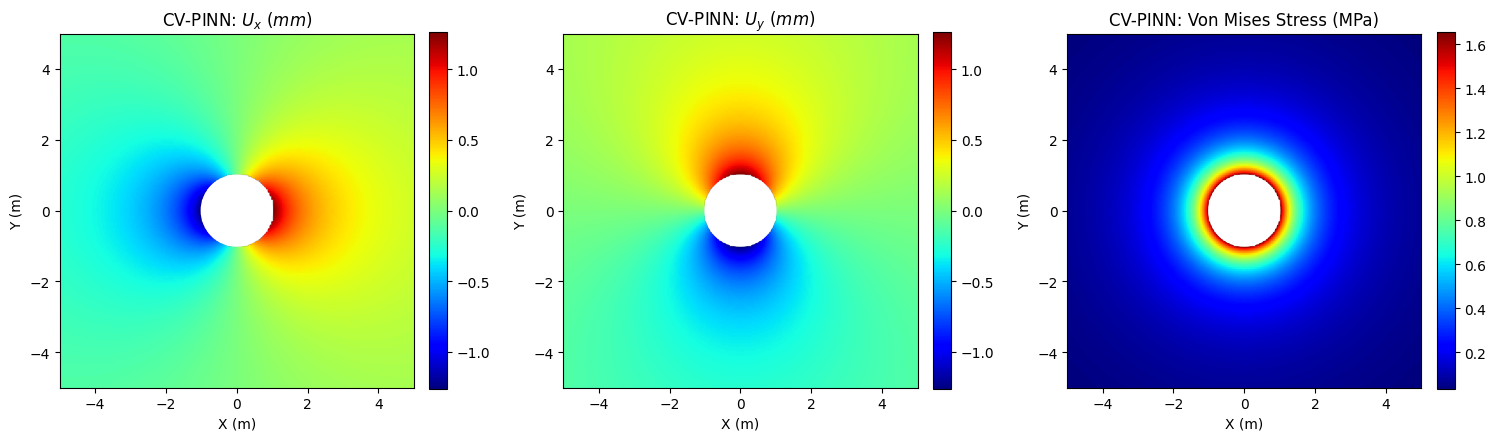

In [11]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import time
import random
import os

# 防止 Windows 下 OpenMP 库重复加载冲突
os.environ["KMP_DUPLICATE_LIB_OK"]="TRUE"

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(42)

# ==========================================
# 1. 物理参数与量纲归一化
# ==========================================
a = 1.0              # 圆孔半径 (m)
P0_real = 1.0e6      # 圆孔内压 (1 MPa)
E_real = 1.0e9       # 杨氏模量 (1.0 GPa)
nu = 0.3             # 泊松比
L_out = 80.0 * a     # 虚拟无限远外边界边长

# 【量纲归一化】
# 以 1 MPa 作为应力基准，网络输出的应力将直接是 MPa。
# 神奇的是，配合真实的 x, y 坐标，输出的位移将刚好是真实位移 (m)！
stress_scale = 1.0e6 
P0 = P0_real / stress_scale  # P0 = 1.0
E = E_real / stress_scale    # E = 1000.0

kappa = 3.0 - 4.0 * nu
G = E / (2.0 * (1.0 + nu))

print(f"=== CV-PINN 求解无限大平面受压圆孔问题 ===")
print(f"归一化参数: E* = {E}, P0* = {P0}, G* = {G:.3f}")

# ==========================================
# 2. 构建复变量神经网络 
# ==========================================
class CVNN(nn.Module):
    def __init__(self, hidden=100):
        super().__init__()
        self.fc1 = nn.Linear(1, hidden, dtype=torch.cfloat)
        self.fc2 = nn.Linear(hidden, hidden, dtype=torch.cfloat)
        self.fc3 = nn.Linear(hidden, hidden, dtype=torch.cfloat)
        self.fc4 = nn.Linear(hidden, hidden, dtype=torch.cfloat) 
        self.out_phi = nn.Linear(hidden, 1, dtype=torch.cfloat)
        self.out_psi = nn.Linear(hidden, 1, dtype=torch.cfloat)
        
        # 【核心修复】：声明可学习的实数参数，组合成复数极点系数 A 和 B
        # 使用实数参数是为了让 PyTorch 的优化器更稳定地追踪梯度
        self.pole_A_R = nn.Parameter(torch.tensor([0.0]))
        self.pole_A_I = nn.Parameter(torch.tensor([0.0]))
        self.pole_B_R = nn.Parameter(torch.tensor([0.0]))
        self.pole_B_I = nn.Parameter(torch.tensor([0.0]))
        
        self._init_weights()

    def _init_weights(self):
        # (保持你原来的初始化代码不变)
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight.real)
                nn.init.xavier_uniform_(m.weight.imag)
                m.weight.data *= (1.0 / np.sqrt(2.0))
                if m.bias is not None:
                    nn.init.constant_(m.bias.real, 0.0)
                    nn.init.constant_(m.bias.imag, 0.0)

    def forward(self, z):
        z_norm = z / 40.0  
        
        x = torch.sin(self.fc1(z_norm))
        x = torch.sin(self.fc2(x))
        x = torch.sin(self.fc3(x))
        x = torch.sin(self.fc4(x))
        
        # 获取纯网络的输出（代表平滑部分）
        phi_mlp = self.out_phi(x)
        psi_mlp = self.out_psi(x)
        
        # 【核心修复】：将网络输出与 Laurent 级数的负幂次项 (1/z) 叠加
        pole_A = torch.complex(self.pole_A_R, self.pole_A_I)
        pole_B = torch.complex(self.pole_B_R, self.pole_B_I)
        
        phi = phi_mlp + pole_A / z
        psi = psi_mlp + pole_B / z
        
        return phi, psi

# ==========================================
# 3. 核心物理场求导引擎
# ==========================================
def get_phys_fields(model, x, y):
    z = torch.complex(x, y)
    phi, psi = model(z)

    phi_R, phi_I = phi.real, phi.imag
    psi_R, psi_I = psi.real, psi.imag

    # 一阶导数
    dphi_dx_R = torch.autograd.grad(phi_R, x, grad_outputs=torch.ones_like(phi_R), create_graph=True, retain_graph=True)[0]
    dphi_dx_I = torch.autograd.grad(phi_I, x, grad_outputs=torch.ones_like(phi_I), create_graph=True, retain_graph=True)[0]
    dpsi_dx_R = torch.autograd.grad(psi_R, x, grad_outputs=torch.ones_like(psi_R), create_graph=True, retain_graph=True)[0]
    dpsi_dx_I = torch.autograd.grad(psi_I, x, grad_outputs=torch.ones_like(psi_I), create_graph=True, retain_graph=True)[0]
    
    dphi_dz = torch.complex(dphi_dx_R, dphi_dx_I)
    dpsi_dz = torch.complex(dpsi_dx_R, dpsi_dx_I)

    # 二阶导数
    d2phi_dx2_R = torch.autograd.grad(dphi_dx_R, x, grad_outputs=torch.ones_like(dphi_dx_R), create_graph=True)[0]
    d2phi_dx2_I = torch.autograd.grad(dphi_dx_I, x, grad_outputs=torch.ones_like(dphi_dx_I), create_graph=True)[0]
    d2phi_dz2 = torch.complex(d2phi_dx2_R, d2phi_dx2_I)

    # 强制将外部的 kappa 和 G 转化为纯净的 PyTorch Tensor，彻底隔绝 NumPy 广播机制的干扰
    kappa_t = torch.tensor(float(kappa), device=x.device)
    G_t = torch.tensor(float(G), device=x.device)

    # 使用转换后的 Tensor 进行物理公式计算
    disp_complex = (kappa_t * phi - z * torch.conj(dphi_dz) - torch.conj(psi)) / (2.0 * G_t)
    # ==============================================

    u_x, u_y = disp_complex.real, disp_complex.imag

    # 计算应力
    sum_sig = 4.0 * dphi_dx_R
    diff_sig = 2.0 * (torch.conj(z) * d2phi_dz2 + dpsi_dz)
    
    sig_xx = (sum_sig - diff_sig.real) / 2.0
    sig_yy = (sum_sig + diff_sig.real) / 2.0
    sig_xy = diff_sig.imag / 2.0

    return u_x, u_y, sig_xx, sig_yy, sig_xy

# ==========================================
# 4. 边界条件采样与损失函数 (圆孔与无限远边界)
# ==========================================
def get_bnd_loss():
    # ---------------- 1. 内圆孔边界 (纯法向内压) ----------------
    N_hole = 360
    theta = torch.linspace(0, 2*np.pi, N_hole).view(-1, 1)
    x_hole = (a * torch.cos(theta)).requires_grad_(True)
    y_hole = (a * torch.sin(theta)).requires_grad_(True)
    
    _, _, sig_xx, sig_yy, sig_xy = get_phys_fields(model, x_hole, y_hole)
    
    # 笛卡尔应力向极坐标应力转换
    cos2 = (x_hole**2 - y_hole**2) / (a**2)
    sin2 = (2 * x_hole * y_hole) / (a**2)
    sig_rr = 0.5*(sig_xx + sig_yy) + 0.5*(sig_xx - sig_yy)*cos2 + sig_xy*sin2
    sig_rt = -0.5*(sig_xx - sig_yy)*sin2 + sig_xy*cos2
    
    # 极坐标应力精确硬约束：径向为 -P0，切向为 0
    loss_hole = torch.mean((sig_rr - (-P0))**2 + (sig_rt - 0.0)**2)

    # ---------------- 2. 外围无限远虚拟边界 (解析位移) ----------------
    N_out = 160 # 单边点数
    coords = torch.linspace(-L_out/2, L_out/2, N_out).view(-1, 1)
    half_L = torch.full_like(coords, L_out/2)
    
    def outer_loss(x_val, y_val):
        x = x_val.clone().detach().requires_grad_(True)
        y = y_val.clone().detach().requires_grad_(True)
        ux_pred, uy_pred, _, _, _ = get_phys_fields(model, x, y)
        r2 = x**2 + y**2
        # 解析位移
        ux_exact = (P0 * a**2 * x) / (2 * G * r2)
        uy_exact = (P0 * a**2 * y) / (2 * G * r2)
        
        # 【关键平衡】由于位移很小，乘以 (2*G) 使其在 Loss 中与应力(O(1))处于相同量级
        l_x = ((ux_pred - ux_exact) * (2*G))**2
        l_y = ((uy_pred - uy_exact) * (2*G))**2
        return torch.mean(l_x + l_y)

    loss_top = outer_loss(coords, half_L)
    loss_bot = outer_loss(coords, -half_L)
    loss_right = outer_loss(half_L, coords)
    loss_left = outer_loss(-half_L, coords)

    return loss_hole + loss_top + loss_bot + loss_right + loss_left

# ==========================================
# 5. 训练网络 (Adam + L-BFGS)
# ==========================================
if __name__ == "__main__":
    model = CVNN(hidden=100)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    epochs_adam = 2000
    print(f"--- 第一阶段：Adam 优化 ({epochs_adam} 次迭代) ---")
    t0 = time.time()
 
    for epoch in range(epochs_adam):
        optimizer.zero_grad()
        loss = get_bnd_loss()
        loss.backward()
        optimizer.step()
        if epoch % 500 == 0:
            print(f"Adam Epoch {epoch:4d} | Loss: {loss.item():.4e}")

    lbfgs_optimizer = torch.optim.LBFGS(
        model.parameters(), lr=1, max_iter=5000, max_eval=6000, 
        history_size=50, tolerance_grad=1e-7, tolerance_change=1e-9, 
        line_search_fn="strong_wolfe" 
    )

    print(f"\n--- 第二阶段：L-BFGS 优化 (高精度收敛) ---")
    iter_count = [0] 

    def closure():
        lbfgs_optimizer.zero_grad()
        loss = get_bnd_loss()
        loss.backward()
        iter_count[0] += 1
        if iter_count[0] % 100 == 0:
            print(f"L-BFGS Iter {iter_count[0]:4d} | Loss: {loss.item():.4e}")
        return loss

    lbfgs_optimizer.step(closure)
    print(f"L-BFGS 完成 | 最终 Loss: {closure().item():.4e}")
    print(f"训练总耗时: {time.time() - t0:.2f} s")

    # ==========================================
    # 6. 全场预测与后处理提取 [-5, 5] 区域
    # ==========================================
    L_plot = 5.0 * a
    grid_size = 200
    coords_1d = np.linspace(-L_plot, L_plot, grid_size)
    XX, YY = np.meshgrid(coords_1d, coords_1d)

    # 屏蔽圆孔内部区域
    r_pts = np.sqrt(XX**2 + YY**2)
    valid_mask = r_pts >= a * 1.02

    X_tensor = torch.tensor(XX[valid_mask].flatten(), dtype=torch.float32).view(-1, 1).requires_grad_(True)
    Y_tensor = torch.tensor(YY[valid_mask].flatten(), dtype=torch.float32).view(-1, 1).requires_grad_(True)

    model.eval()
    u_x_pred, u_y_pred, sig_xx_pred, sig_yy_pred, sig_xy_pred = get_phys_fields(model, X_tensor, Y_tensor)

    # 由于精妙的量纲推导，u_pred 天生就是真实位移 (m)，乘以 1e3 转为 mm
    u_x_mm = u_x_pred.detach().numpy().flatten() * 1e3
    u_y_mm = u_y_pred.detach().numpy().flatten() * 1e3
    
    # 预测应力自带归一化尺度，天生就是 MPa
    sig_xx_MPa = sig_xx_pred.detach().numpy().flatten()
    sig_yy_MPa = sig_yy_pred.detach().numpy().flatten()
    sig_xy_MPa = sig_xy_pred.detach().numpy().flatten()

    sig_zz_MPa = nu * (sig_xx_MPa + sig_yy_MPa)
    von_mises_MPa = np.sqrt(0.5 * ((sig_xx_MPa - sig_yy_MPa)**2 + 
                                   (sig_yy_MPa - sig_zz_MPa)**2 + 
                                   (sig_zz_MPa - sig_xx_MPa)**2) + 
                            3 * sig_xy_MPa**2)

    # 映射回 2D 图片阵列
    U_X_map = np.full((grid_size, grid_size), np.nan)
    U_X_map[valid_mask] = u_x_mm
    
    U_Y_map = np.full((grid_size, grid_size), np.nan)
    U_Y_map[valid_mask] = u_y_mm
    
    VM_map = np.full((grid_size, grid_size), np.nan)
    VM_map[valid_mask] = von_mises_MPa

    # ==========================================
    # 7. 绘图出图 (与之前的 BEM 一一对应)
    # ==========================================
    import matplotlib.gridspec as gridspec

    fig = plt.figure(figsize=(18, 5))
    gs = gridspec.GridSpec(1, 3, figure=fig, wspace=0.3)
    extent = [-L_plot, L_plot, -L_plot, L_plot]

    # Ux 位移 (mm)
    ax0 = fig.add_subplot(gs[0, 0])
    im0 = ax0.imshow(U_X_map, origin='lower', extent=extent, cmap='jet')
    ax0.set_xlabel('X (m)'); ax0.set_ylabel('Y (m)')
    fig.colorbar(im0, ax=ax0, fraction=0.046, pad=0.04)
    ax0.set_title('CV-PINN: $U_x$ ($mm$)')
    ax0.add_patch(plt.Circle((0, 0), a, color='white', fill=True))

    # Uy 位移 (mm)
    ax1 = fig.add_subplot(gs[0, 1])
    im1 = ax1.imshow(U_Y_map, origin='lower', extent=extent, cmap='jet')
    ax1.set_xlabel('X (m)'); ax1.set_ylabel('Y (m)')
    fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)
    ax1.set_title('CV-PINN: $U_y$ ($mm$)')
    ax1.add_patch(plt.Circle((0, 0), a, color='white', fill=True))

    # Von Mises 应力 (MPa)
    ax2 = fig.add_subplot(gs[0, 2])
    im2 = ax2.imshow(VM_map, origin='lower', extent=extent, cmap='jet')
    ax2.set_xlabel('X (m)'); ax2.set_ylabel('Y (m)')
    fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)
    ax2.set_title('CV-PINN: Von Mises Stress (MPa)')
    ax2.add_patch(plt.Circle((0, 0), a, color='white', fill=True))

    plt.show()


=== 开始计算 CV-PINN 与 BEM 之间的误差 ===
--------------------------------------------------
Relative L2 error Ux: 2.795e-03
Relative L2 error Uy: 2.801e-03
Max Normalized Error Ux: 2.843e-03
Max Normalized Error Uy: 2.798e-03
--------------------------------------------------


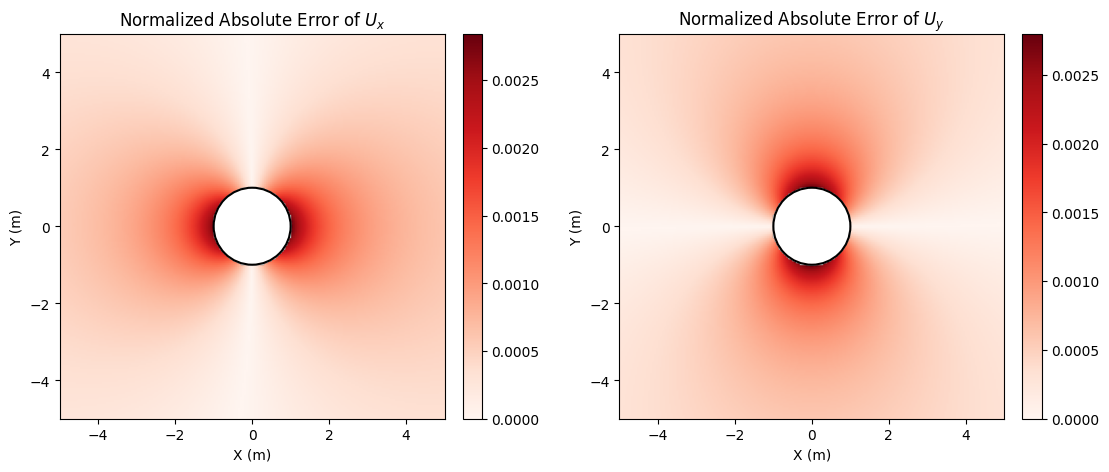

In [15]:
# ==========================================
# 8. CV-PINN 相对于 BEM 参考解的位移误差分析 (圆孔受压算例)
# ==========================================
print("\n=== 开始计算 CV-PINN 与 BEM 之间的误差 ===")

# 1. 准备测试点：开启梯度以适配 PINN 的物理场求导引擎
# 注意：这里的 internal_pts 直接继承自你刚刚运行的 BEM 代码
X_bem = torch.tensor(internal_pts[:, 0:1], dtype=torch.float32, requires_grad=True)
Y_bem = torch.tensor(internal_pts[:, 1:2], dtype=torch.float32, requires_grad=True)

# 2. CV-PINN 模型预测
model.eval() 
u_pred_bem, v_pred_bem, _, _, _ = get_phys_fields(model, X_bem, Y_bem)

# 圆孔算例中，归一化推导使得预测位移天生就是真实位移 (m)
u_pred_real = u_pred_bem.detach().numpy().flatten()
v_pred_real = v_pred_bem.detach().numpy().flatten()

# 提取 BEM 参考解 (m)
u_bem_ref = u_int[:, 0]
v_bem_ref = u_int[:, 1]

# 3. 计算误差指标
# 归一化因子：使用 BEM 参考解的全场绝对最大值
norm_factor_ux = max(np.max(np.abs(u_bem_ref)), 1e-15)
norm_factor_uy = max(np.max(np.abs(v_bem_ref)), 1e-15)

# 计算每个数据点的绝对归一化误差
err_ux_norm = np.abs(u_pred_real - u_bem_ref) / norm_factor_ux
err_uy_norm = np.abs(v_pred_real - v_bem_ref) / norm_factor_uy

# 计算全场相对 L2 误差 (衡量全局拟合质量)
L2_ux = np.linalg.norm(u_pred_real - u_bem_ref, 2) / max(np.linalg.norm(u_bem_ref, 2), 1e-15)
L2_uy = np.linalg.norm(v_pred_real - v_bem_ref, 2) / max(np.linalg.norm(v_bem_ref, 2), 1e-15)

print("-" * 50)
print(f"Relative L2 error Ux: {L2_ux:.3e}")
print(f"Relative L2 error Uy: {L2_uy:.3e}")
print(f"Max Normalized Error Ux: {err_ux_norm.max():.3e}")
print(f"Max Normalized Error Uy: {err_uy_norm.max():.3e}")
print("-" * 50)

# ==========================================
# 4. 映射回 2D 网格并绘图 (与 BEM 绘图逻辑保持一致)
# ==========================================
import matplotlib.gridspec as gridspec

# 【关键修复】：强制将 valid_mask 展平，屏蔽历史变量的维度干扰
valid_mask_1d = valid_mask.flatten()

Err_X_map = np.full(grid_size * grid_size, np.nan)
Err_X_map[valid_mask_1d] = err_ux_norm

Err_Y_map = np.full(grid_size * grid_size, np.nan)
Err_Y_map[valid_mask_1d] = err_uy_norm

fig = plt.figure(figsize=(13, 5))
gs = gridspec.GridSpec(1, 2, figure=fig, wspace=0.25)
extent = [-L_plot, L_plot, -L_plot, L_plot]

# --- Ux 归一化误差图 ---
ax0 = fig.add_subplot(gs[0, 0])
im0 = ax0.imshow(Err_X_map.reshape(grid_size, grid_size), origin='lower', extent=extent, cmap='Reds', vmin=0)
ax0.set_xlabel('X (m)')
ax0.set_ylabel('Y (m)')
ax0.set_title('Normalized Absolute Error of $U_x$')
# 画出白色的中心圆，遮盖 NaN 区域，保持图片整洁
ax0.add_patch(plt.Circle((0, 0), a, color='white', fill=True))
# 加上一圈黑色的孔洞边界线，增加辨识度
ax0.add_patch(plt.Circle((0, 0), a, color='black', fill=False, linewidth=1.5, linestyle='-'))
fig.colorbar(im0, ax=ax0, fraction=0.046, pad=0.04)

# --- Uy 归一化误差图 ---
ax1 = fig.add_subplot(gs[0, 1])
im1 = ax1.imshow(Err_Y_map.reshape(grid_size, grid_size), origin='lower', extent=extent, cmap='Reds', vmin=0)
ax1.set_xlabel('X (m)')
ax1.set_ylabel('Y (m)')
ax1.set_title('Normalized Absolute Error of $U_y$')
# 画出白色的中心圆及边界
ax1.add_patch(plt.Circle((0, 0), a, color='white', fill=True))
ax1.add_patch(plt.Circle((0, 0), a, color='black', fill=False, linewidth=1.5, linestyle='-'))
fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)

plt.show()